## Entrenamiento de algoritmos de clasificación

### Clasificación Motivo de consulta



In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

stop_words = pd.read_excel(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\stop words spanish.xlsx")
SPANISH_STOP_WORDS = set(stop_words.iloc[:, 0].str.lower().tolist())

In [2]:



df_evaluate=pd.read_excel("C:/Users/raultc/Documents/MAA/PROYECTO/proyecto final/Audit HC (2).xlsx")
df_f = df_evaluate.dropna(subset=['Motivo de consulta', 'Enfermedad actual', 'Examen Físico', 'Diagnóstico'])

In [3]:

RANDOM_STATE = 42
CRITERIO     = "Motivo de consulta"     # columna del experto
N_FOLDS = 5
CV = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Tokenizador que conserva tildes y ñ
def tokenizar(texto):
    return re.findall(r"[a-záéíóúüñ]+", str(texto).lower())



df_exp = df_f.copy().reset_index(drop=True)
df_exp["caso"] = df_exp["caso"].astype(str)
df_exp["texto_sin_alterar"]  = df_exp["nota"].apply(lambda t: " ".join(tokenizar(t)))
df_exp["texto_sin_stopwords"] = df_exp["nota"].apply(
    lambda t: " ".join(w for w in tokenizar(t) if w not in SPANISH_STOP_WORDS))


y = df_exp[CRITERIO].astype(int).values
print(f"{CRITERIO}: {len(y)} notas | cumple: {(y == 1).sum()} | no cumple: {(y == 0).sum()}")

Motivo de consulta: 98 notas | cumple: 80 | no cumple: 18


In [4]:
df_exp

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,texto_sin_alterar,texto_sin_stopwords
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años...,432.0,0.432558,1.0,1.0,1.0,1.0,se presenta un caso de una paciente de años qu...,se presenta caso de paciente de años que acude...
1,S1130-05582008000400008-3,Varón de 44 años ingresado por trauma facial. ...,69.0,0.362319,1.0,0.0,0.0,1.0,varón de años ingresado por trauma facial el e...,varón de años ingresado trauma facial estudio ...
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés q...,148.0,0.412162,1.0,1.0,1.0,1.0,mujer de años sin antecedentes de interés que ...,mujer de años antecedentes de interés que cons...
3,S0212-16112008000500014-1,Varón de 78 años que ingresa en Medicina Inter...,NaN,NaN,1.0,1.0,1.0,0.0,varón de años que ingresa en medicina interna ...,varón de años que ingresa medicina interna del...
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemo...,224.0,0.384615,0.0,1.0,0.0,1.0,mujer de años cirrótica vhc asociada a hemocro...,mujer de años cirrótica vhc asociada a hemocro...
...,...,...,...,...,...,...,...,...,...,...
93,S0365-66912011001000003-1,El primer caso es el de una niña de 9 años de ...,169.0,0.534591,1.0,1.0,1.0,0.0,el primer caso es el de una niña de años de ed...,primer caso de niña de años de edad que referí...
94,S0376-78922007000300006-3,"Varón de 20 años, pescador, sin antecedentes m...",118.0,0.456140,0.0,1.0,1.0,0.0,varón de años pescador sin antecedentes médico...,varón de años pescador antecedentes médicos de...
95,S1887-85712013000200013-1,"Paciente de 3 años (94 cm, 10 Kg), niña, afgan...",167.0,0.388535,1.0,1.0,1.0,0.0,paciente de años cm kg niña afgana con signos ...,paciente de años cm kg niña afgana signos de d...
96,S0212-71992006000900007-1,Varón de 51 años que acudió a las consultas de...,337.0,0.455357,1.0,1.0,1.0,1.0,varón de años que acudió a las consultas de de...,varón de años que acudió a consultas de dermat...


### Representaciones

- **BoW**: conteo de palabras.
- **TF-IDF**: conteo ponderado por lo rara que es cada palabra en el corpus.
- **W2V**: promedio de los vectores Word2Vec de las palabras de la nota.
- **W2V + TF-IDF**: promedio de los vectores Word2Vec ponderado por el peso TF-IDF de cada palabra.

Todas van dentro de un pipeline, así que en cada fold se entrenan **solo con las notas de train**

Notas del experto: 98 | cumple: 80 | no cumple: 18
✓ Sin números – BoW
✓ Sin números – TF-IDF
✓ Sin números – W2V
✓ Sin números – W2V + TF-IDF
✓ Con números – BoW
✓ Con números – TF-IDF
✓ Con números – W2V
✓ Con números – W2V + TF-IDF
✓ Número genérico – BoW
✓ Número genérico – TF-IDF
✓ Número genérico – W2V
✓ Número genérico – W2V + TF-IDF


F1_media  F1_desv  Recall_No_cumple  Acc_media
Tokenización    Representación                                                
Sin números     TF-IDF             0.643    0.150             0.350      0.816
Con números     TF-IDF             0.617    0.140             0.300      0.807
                W2V + TF-IDF       0.583    0.148             0.333      0.775
Sin números     W2V + TF-IDF       0.583    0.132             0.400      0.733
Número genérico W2V + TF-IDF       0.583    0.118             0.350      0.754
                TF-IDF             0.576    0.161             0.283      0.776
Con números     BoW                0.567    0.078             0.233      0.785
Sin números     W2V                0.515    0.064             0.683      0.571
                BoW                0.507    0.102             0.100      0.786
Número genérico BoW                0.507    0.102             0.100      0.786
                W2V                0.496    0.161             0.550      0.559
Con números     W2V                0.460    0.070             0.433      0.541

Tokenización,Sin números,Con números,Número genérico
Representación,,,
BoW,0.507 ± 0.102,0.567 ± 0.078,0.507 ± 0.102
TF-IDF,0.643 ± 0.150,0.617 ± 0.140,0.576 ± 0.161
W2V,0.515 ± 0.064,0.460 ± 0.070,0.496 ± 0.161
W2V + TF-IDF,0.583 ± 0.132,0.583 ± 0.148,0.583 ± 0.118


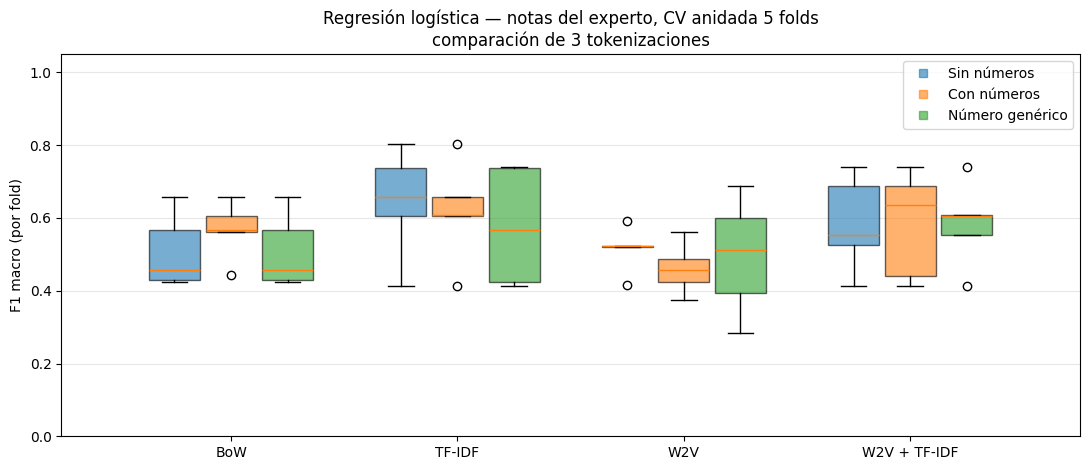

In [5]:
# =====================================================================
# CLASIFICACIÓN — ¿Qué tokenización clasifica mejor?
# Notas del EXPERTO (df_exp) · Regresión logística (elastic net)
# Validación cruzada anidada, igual que la celda 10:
#   CV externo = 5 folds (mide F1) | CV interno = 3 folds (elige C y l1_ratio)
# 3 tokenizaciones × 4 representaciones
# =====================================================================
import re, unicodedata, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score
from sklearn.exceptions import ConvergenceWarning

RANDOM_STATE = 42

# 1) Datos: notas y etiquetas del experto
datos = df_exp[df_exp["Motivo de consulta"].notna()].reset_index(drop=True)
y_exp = datos["Motivo de consulta"].astype(int).to_numpy()
print(f"Notas del experto: {len(y_exp)} | cumple: {(y_exp == 1).sum()} | no cumple: {(y_exp == 0).sum()}")

# 2) Las 3 tokenizaciones -> 3 columnas de texto
def _normalizar(texto):
    return unicodedata.normalize("NFC", str(texto)).lower()

def tok_sin_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+", _normalizar(texto))

def tok_con_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+|\d+", _normalizar(texto))

def tok_num_generico(texto):
    return re.findall(r"[a-záéíóúüñ]+", re.sub(r"\d+", " num ", _normalizar(texto)))

TOKENIZACIONES = {"Sin números": tok_sin_numeros,
                  "Con números": tok_con_numeros,
                  "Número genérico": tok_num_generico}

TEXTOS_TOK = {}
for nombre_tok, tok in TOKENIZACIONES.items():
    TEXTOS_TOK[nombre_tok] = datos["nota"].fillna("").apply(lambda t: " ".join(tok(t)))

# 3) Representaciones (misma configuración que REPRESENTACIONES).
#    W2V con su propio .split(): no depende de la función global `tokenizar`.
class W2VClf(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100, window=5, min_count=2, seed=42):
        self.vector_size, self.window = vector_size, window
        self.min_count, self.seed = min_count, seed

    def fit(self, X, y=None):
        self.w2v_ = Word2Vec([str(t).split() for t in X], vector_size=self.vector_size,
                             window=self.window, min_count=self.min_count,
                             seed=self.seed, workers=1)
        return self

    def transform(self, X):
        filas = []
        for t in X:
            vecs = [self.w2v_.wv[p] for p in str(t).split() if p in self.w2v_.wv]
            filas.append(np.mean(vecs, axis=0) if vecs else np.zeros(self.vector_size))
        return np.vstack(filas)

REPS_CLF = {
    "BoW":          lambda: CountVectorizer(min_df=2),
    "TF-IDF":       lambda: TfidfVectorizer(ngram_range=(1, 3), min_df=3),
    "W2V":          lambda: W2VClf(),
    "W2V + TF-IDF": lambda: FeatureUnion([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
        ("w2v",   W2VClf()),
    ]),
}

# 4) Regresión logística + búsqueda de hiperparámetros (igual que la celda 10)
GRILLA = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__l1_ratio": [0.0, 0.5, 1.0],     # 0 = L2, 1 = L1
}

def pipeline_logistica(nombre_rep):
    densa = nombre_rep == "W2V"
    return Pipeline([
        ("rep", REPS_CLF[nombre_rep]()),
        ("esc", StandardScaler() if densa else MaxAbsScaler()),
        ("clf", LogisticRegression(solver="saga", penalty="elasticnet", tol=1e-4,
                                   class_weight="balanced", max_iter=5000,
                                   random_state=RANDOM_STATE)),
    ])

cv_externo = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# 5) Validación cruzada anidada: 3 tokenizaciones × 4 representaciones
#    (los mismos folds para todas, así la comparación es justa)
folds = list(cv_externo.split(datos, y_exp))
filas_clf, pred_tok = [], {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    warnings.simplefilter("ignore", FutureWarning)
    for nombre_tok, textos in TEXTOS_TOK.items():
        for nombre_rep in REPS_CLF:
            pred_oof = np.empty(len(y_exp), dtype=int)
            for i, (tr, te) in enumerate(folds):
                busqueda = GridSearchCV(pipeline_logistica(nombre_rep), GRILLA,
                                        scoring="f1_macro", cv=cv_interno, n_jobs=-1)
                busqueda.fit(textos.iloc[tr], y_exp[tr])
                y_pred = busqueda.predict(textos.iloc[te])
                pred_oof[te] = y_pred
                filas_clf.append({
                    "Tokenización": nombre_tok,
                    "Representación": nombre_rep,
                    "Fold": i,
                    "F1 macro": f1_score(y_exp[te], y_pred, average="macro"),
                    "Recall No cumple": recall_score(y_exp[te], y_pred, pos_label=0),
                    "Accuracy": accuracy_score(y_exp[te], y_pred),
                    "C": busqueda.best_params_["clf__C"],
                    "l1_ratio": busqueda.best_params_["clf__l1_ratio"],
                })
            pred_tok[(nombre_tok, nombre_rep)] = pred_oof
            print(f"✓ {nombre_tok} – {nombre_rep}")

df_folds_tok = pd.DataFrame(filas_clf)

# 6) Resultados
resumen_tok = (df_folds_tok
    .groupby(["Tokenización", "Representación"], sort=False)
    .agg(F1_media=("F1 macro", "mean"), F1_desv=("F1 macro", "std"),
         Recall_No_cumple=("Recall No cumple", "mean"), Acc_media=("Accuracy", "mean"))
    .sort_values("F1_media", ascending=False)
    .round(3))
display(resumen_tok)

# Tabla compacta: F1 macro (media ± desv) por representación y tokenización
tabla_f1 = (df_folds_tok.groupby(["Representación", "Tokenización"], sort=False)["F1 macro"]
            .agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}")
            .unstack()[list(TOKENIZACIONES)])
display(tabla_f1)

# Boxplot del F1 por fold
fig, ax = plt.subplots(figsize=(11, 4.8))
reps = list(REPS_CLF)
ancho = 0.25
for k, nombre_tok in enumerate(TOKENIZACIONES):
    datos_box = [df_folds_tok.query("Tokenización == @nombre_tok and Representación == @r")["F1 macro"]
                 for r in reps]
    pos = np.arange(len(reps)) + (k - 1) * ancho
    bp = ax.boxplot(datos_box, positions=pos, widths=ancho * 0.9, patch_artist=True)
    for caja in bp["boxes"]:
        caja.set_facecolor(f"C{k}"); caja.set_alpha(0.6)
    ax.plot([], [], "s", color=f"C{k}", alpha=0.6, label=nombre_tok)
ax.set_xticks(np.arange(len(reps))); ax.set_xticklabels(reps)
ax.set(ylabel="F1 macro (por fold)", ylim=(0, 1.05),
       title="Regresión logística — notas del experto, CV anidada 5 folds\n"
             "comparación de 3 tokenizaciones")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("f1_tokenizaciones_logistica.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
import numpy as np
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion

def tokenizar(texto):
    return str(texto).lower().split()

class W2VPromedio(BaseEstimator, TransformerMixin):
    """Entrena Word2Vec con los textos de train y representa cada nota
    como el promedio de los vectores de sus palabras."""
    def __init__(self, vector_size=100, window=5, min_count=2, seed=42):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.seed = seed

    def fit(self, X, y=None):
        frases = [tokenizar(t) for t in X]
        self.w2v_ = Word2Vec(frases, vector_size=self.vector_size, window=self.window,
                             min_count=self.min_count, seed=self.seed, workers=1)
        return self

    def transform(self, X):
        filas = []
        for t in X:
            vecs = [self.w2v_.wv[p] for p in tokenizar(t) if p in self.w2v_.wv]
            filas.append(np.mean(vecs, axis=0) if vecs else np.zeros(self.vector_size))
        return np.vstack(filas)

REPRESENTACIONES = {
    "BoW":        lambda: CountVectorizer(min_df=2),
    "TF-IDF":     lambda: TfidfVectorizer(ngram_range=(1, 3), min_df=3),
    "W2V":        lambda: W2VPromedio(),
    "W2V + TF-IDF": lambda: FeatureUnion([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
        ("w2v",   W2VPromedio()),
    ]),
}

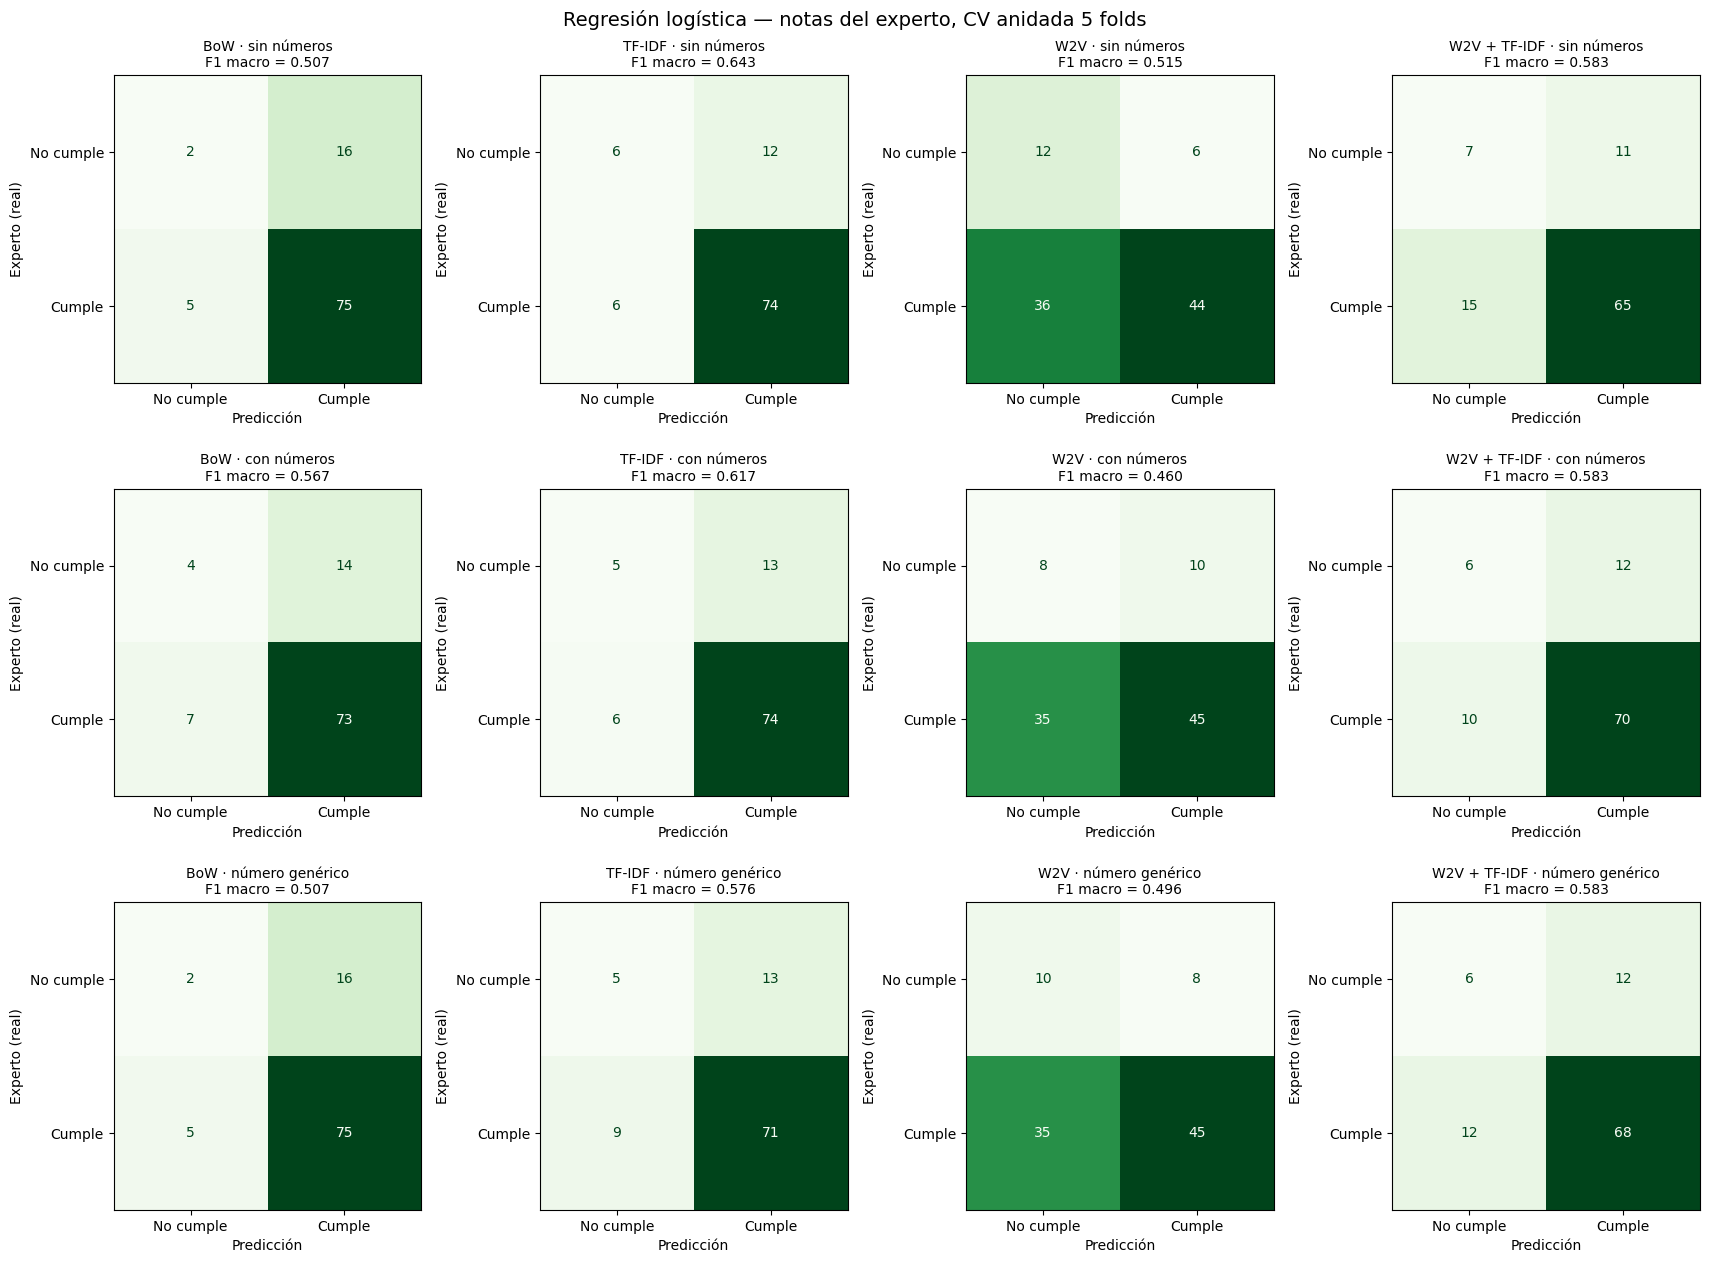

In [7]:
# =====================================================================
# Matrices de confusión — 3 tokenizaciones × 4 representaciones
# Predicciones out-of-fold de la CV anidada (cada nota se predice una vez,
# cuando estaba en el fold de test)
# =====================================================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

n_filas, n_cols = len(TOKENIZACIONES), len(REPS_CLF)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.3 * n_cols, 4.3 * n_filas), squeeze=False)

for fila_ax, nombre_tok in zip(axes, TOKENIZACIONES):
    for ax, nombre_rep in zip(fila_ax, REPS_CLF):
        cm = confusion_matrix(y_exp, pred_tok[(nombre_tok, nombre_rep)], labels=[0, 1])
        f1 = resumen_tok.loc[(nombre_tok, nombre_rep), "F1_media"]
        ConfusionMatrixDisplay(cm, display_labels=["No cumple", "Cumple"]).plot(
            ax=ax, cmap="Greens", colorbar=False, values_format="d")
        ax.set_title(f"{nombre_rep} · {nombre_tok.lower()}\nF1 macro = {f1:.3f}", fontsize=10)
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Experto (real)")

plt.suptitle("Regresión logística — notas del experto, CV anidada 5 folds", fontsize=14)
plt.tight_layout()
plt.savefig("matrices_confusion_tokenizaciones.png", dpi=200, bbox_inches="tight")
plt.show()

Se elige tf-idf con numeros ya que clasifica un poco mejor los no cumplen

In [8]:
# =====================================================================
# CELDA 1 — Revisar la dimensión de los vectores de cada representación
# Pégala después de la celda donde defines REPRESENTACIONES y clasificador().
# Mide los vectores DENTRO de cada fold (solo con las notas de train),
# que es exactamente lo que recibe la regresión logística.
# =====================================================================
from scipy import sparse
from collections import Counter

TEXTOS = {"Con stopwords": "texto_sin_alterar", "sin stopwords": "texto_sin_stopwords"}

def medir_vectores(rep, textos):
    """Ajusta la representación y devuelve (n_notas, n_dimensiones, densidad, activas_por_nota)."""
    X = rep.fit_transform(textos)
    n, d = X.shape
    if sparse.issparse(X):
        densidad = X.nnz / (n * d)
        activas = X.getnnz(axis=1).mean()
    else:
        densidad = np.count_nonzero(X) / X.size
        activas = np.count_nonzero(X, axis=1).mean()
    return n, d, densidad, activas

filas_dim = []
for nombre_texto, col_texto in TEXTOS.items():
    for nombre_rep, crear_rep in REPRESENTACIONES.items():
        res = np.array([medir_vectores(crear_rep(), df_exp[col_texto].iloc[tr])
                        for tr, _ in CV.split(df_exp[col_texto], y)])
        n_train, dims = res[:, 0].mean(), res[:, 1]
        filas_dim.append({
            "Texto": nombre_texto,
            "Representación": nombre_rep,
            "Notas train (por fold)": int(n_train),
            "Dimensiones (media)": int(dims.mean()),
            "Dim. mín–máx entre folds": f"{int(dims.min())}–{int(dims.max())}",
            "Dimensiones / notas": round(dims.mean() / n_train, 1),
            "% celdas ≠ 0": round(res[:, 2].mean() * 100, 1),
            "Dimensiones activas por nota": int(res[:, 3].mean()),
        })

df_dim = pd.DataFrame(filas_dim)
display(df_dim)

# Contexto: cuántas notas hay por clase en train (la clase minoritaria es la que limita)
n_min = int((y == 0).sum() * (N_FOLDS - 1) / N_FOLDS)
print(f"Clase minoritaria ('No cumple') en train por fold: ~{n_min} notas")



,Texto,Representación,Notas train (por fold),Dimensiones (media),Dim. mín–máx entre folds,Dimensiones / notas,% celdas ≠ 0,Dimensiones activas por nota
0,Con stopwords,BoW,78,2075,2026–2166,26.5,7.0,146
1,Con stopwords,TF-IDF,78,2695,2628–2802,34.4,8.4,227
2,Con stopwords,W2V,78,100,100–100,1.3,100.0,100
3,Con stopwords,W2V + TF-IDF,78,2795,2728–2902,35.7,11.7,327
4,sin stopwords,BoW,78,2004,1959–2093,25.6,6.4,127
5,sin stopwords,TF-IDF,78,1998,1952–2046,25.5,8.0,160
6,sin stopwords,W2V,78,100,100–100,1.3,100.0,100
7,sin stopwords,W2V + TF-IDF,78,2098,2052–2146,26.8,12.4,260


Clase minoritaria ('No cumple') en train por fold: ~14 notas


#### Los numeros pierden información??


- Elegir el clasificador

In [9]:
from functools import partial
from sklearn.linear_model import LogisticRegression

clasificador = partial(
    LogisticRegression,
    tol=1e-4,                 # saga converge lento con BoW/TF-IDF
    class_weight="balanced",   # compensa el desbalance (~14 "No cumple" por fold)
    max_iter=5000,             # saga converge lento, sobre todo con BoW/TF-IDF
    random_state=RANDOM_STATE,
)

In [10]:
# =====================================================================
# CELDA 2 — Parametrizar la regresión logística por representación
# Validación cruzada anidada: CV externo = tu CV; CV interno = búsqueda de C y l1_ratio
# =====================================================================
from tempfile import mkdtemp
from shutil import rmtree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score

GRILLA = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__l1_ratio": [0.0, 0.5, 1.0],   # 0 = L2, 1 = L1
}

def construir_pipeline(nombre_rep, crear_rep, cache):
    densa = nombre_rep == "W2V"
    return Pipeline([
        ("rep", crear_rep()),
        ("esc", StandardScaler() if densa else MaxAbsScaler()),
        ("clf", clasificador(solver="saga", penalty="elasticnet")),
    ], memory=cache)

y = np.asarray(y)
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cache = mkdtemp()

filas, predicciones = [], {}
for nombre_texto, col_texto in TEXTOS.items():
    textos = df_exp[col_texto]
    for nombre_rep, crear_rep in REPRESENTACIONES.items():
        pred_oof = np.empty(len(y), dtype=int)
        for i, (tr, te) in enumerate(CV.split(textos, y)):
            busqueda = GridSearchCV(
                construir_pipeline(nombre_rep, crear_rep, cache), GRILLA,
                scoring="f1_macro", cv=cv_interno, n_jobs=1,
            )
            busqueda.fit(textos.iloc[tr], y[tr])
            y_pred = busqueda.predict(textos.iloc[te])
            pred_oof[te] = y_pred
            filas.append({
                "Texto": nombre_texto,
                "Representación": nombre_rep,
                "Fold": i,
                "F1 macro test": f1_score(y[te], y_pred, average="macro"),
                "Recall test": recall_score(y[te], y_pred),      # recall de "Cumple" (1)
                "Accuracy test": accuracy_score(y[te], y_pred),
            })
        predicciones[(nombre_texto, nombre_rep)] = pred_oof
        print(f"✓ {nombre_texto} – {nombre_rep}")

rmtree(cache)
df_folds = pd.DataFrame(filas)

resumen = (df_folds
    .groupby(["Texto", "Representación"], sort=False)
    .agg(F1_media=("F1 macro test", "mean"),
         Recall_Cumple=("Recall test", "mean"),
         Acc_media=("Accuracy test", "mean"),
    )
    .sort_values("F1_media", ascending=False)
    .round(3))
display(resumen)

c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – BoW


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – TF-IDF


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – W2V


... (7 outputs left out)

✓ sin stopwords – W2V


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ sin stopwords – W2V + TF-IDF


F1_media  Recall_Cumple  Acc_media
Texto         Representación                                    
Con stopwords TF-IDF             0.643          0.925      0.816
sin stopwords W2V + TF-IDF       0.636          0.788      0.744
              BoW                0.600          0.900      0.785
              TF-IDF             0.594          0.850      0.755
Con stopwords W2V + TF-IDF       0.583          0.812      0.733
              W2V                0.515          0.550      0.571
sin stopwords W2V                0.508          0.612      0.591
Con stopwords BoW                0.507          0.938      0.786

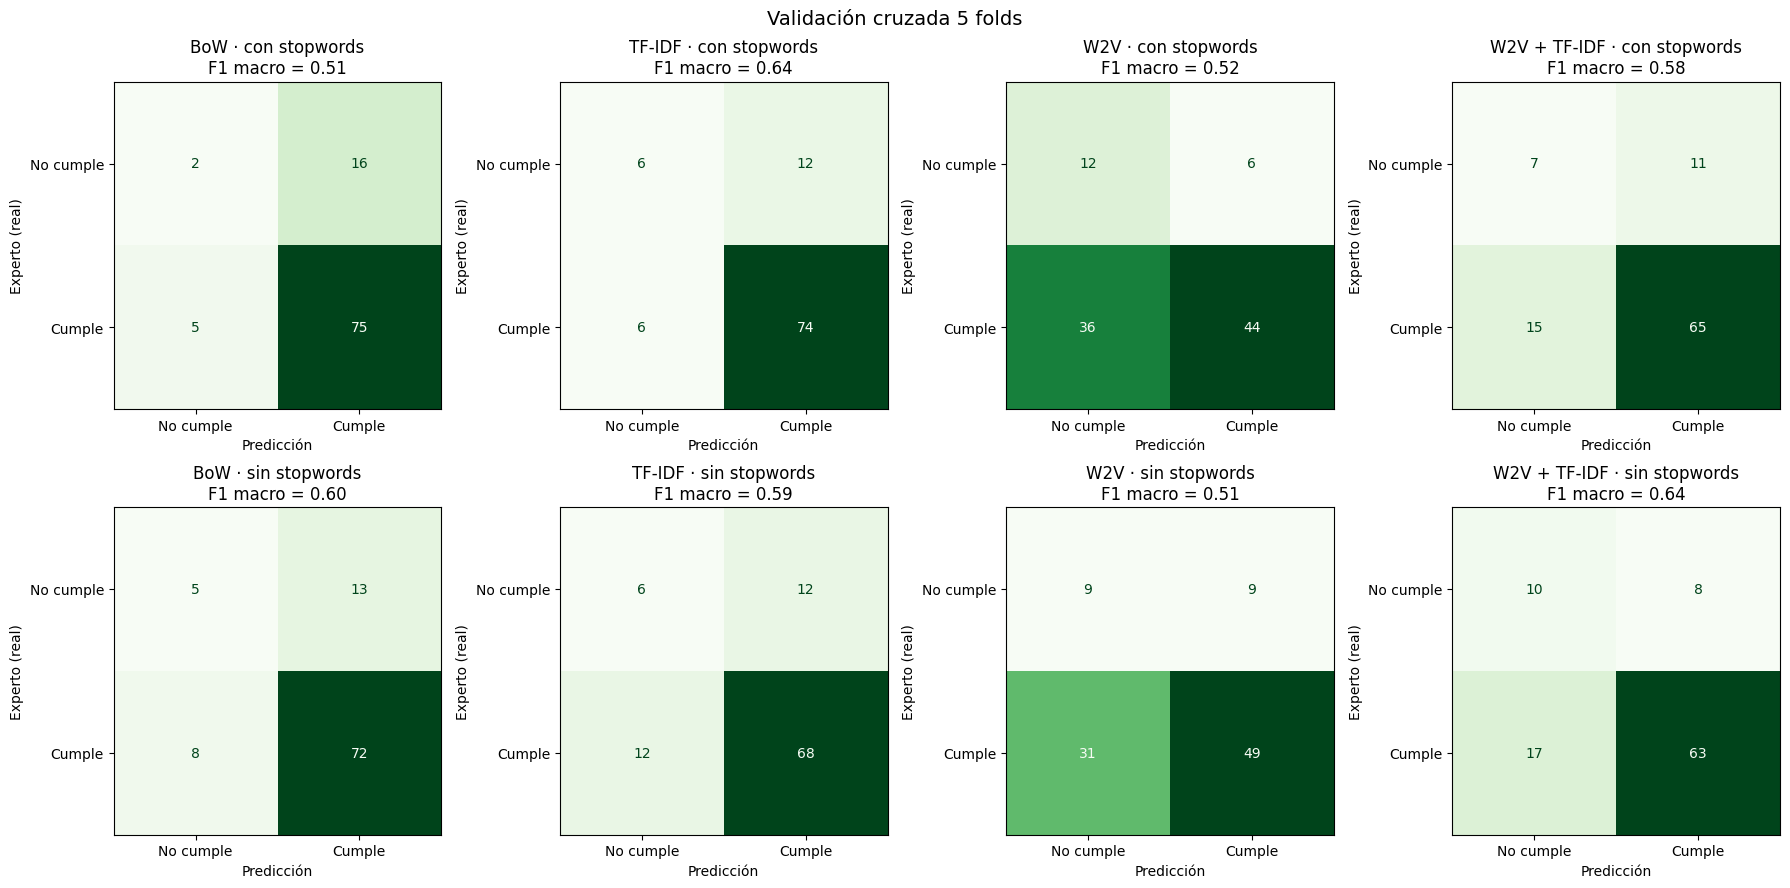

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

n_filas, n_cols = len(TEXTOS), len(REPRESENTACIONES)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.5 * n_cols, 4.5 * n_filas), squeeze=False)

for fila_ax, nombre_texto in zip(axes, TEXTOS):
    for ax, nombre_rep in zip(fila_ax, REPRESENTACIONES):
        cm = confusion_matrix(y, predicciones[(nombre_texto, nombre_rep)], labels=[0, 1])
        f1 = resumen.loc[(nombre_texto, nombre_rep), "F1_media"]
        ConfusionMatrixDisplay(cm, display_labels=["No cumple", "Cumple"]).plot(
            ax=ax, cmap="Greens", colorbar=False, values_format="d")
        ax.set_title(f"{nombre_rep} · {nombre_texto.lower()}\nF1 macro = {f1:.2f}")
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Experto (real)")

plt.suptitle(f"Validación cruzada {CV.get_n_splits()} folds", fontsize=14)
plt.tight_layout()
plt.show()

## Entrenamiento del mejor modelo

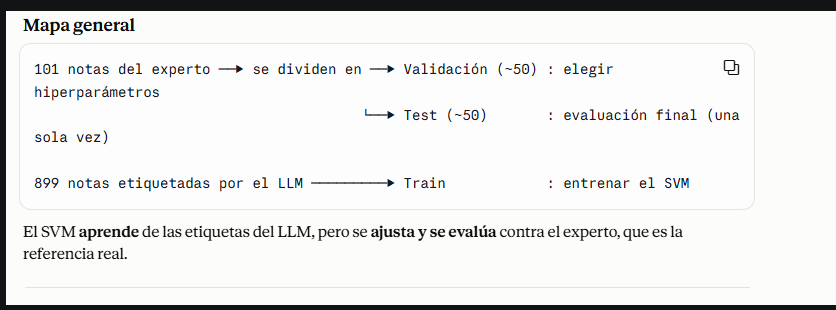

### Experimentos 


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (f1_score, recall_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

CRIT = "Motivo de consulta"

In [13]:
df_exp = pd.read_excel(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\Audit HC (2).xlsx", sheet_name="Sheet1")
df_exp["caso"] = df_exp["caso"].astype(str)

In [17]:
df_exp

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años...,432.0,0.432558,1.0,1.0,1.0,1.0
1,S1130-05582008000400008-3,Varón de 44 años ingresado por trauma facial. ...,69.0,0.362319,1.0,0.0,0.0,1.0
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés q...,148.0,0.412162,1.0,1.0,1.0,1.0
3,S0212-16112008000500014-1,Varón de 78 años que ingresa en Medicina Inter...,NaN,NaN,1.0,1.0,1.0,0.0
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemo...,224.0,0.384615,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,251.0,0.483607,NaN,NaN,NaN,NaN
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,146.0,0.355072,NaN,NaN,NaN,NaN
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,269.0,0.470149,NaN,NaN,NaN,NaN
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,281.0,0.418251,NaN,NaN,NaN,NaN


In [14]:
COL_EXP = "Motivo de consulta"

# Si alguna nota se usó como ejemplo few-shot, se excluye de la evaluación
IDS_EJEMPLOS = set()          # p. ej. {"12", "45"}
df_exp = df_exp[~df_exp["caso"].isin(IDS_EJEMPLOS)]
df_exp = df_exp[df_exp[COL_EXP].notna()]

print("Notas del experto:", len(df_exp))
print(df_exp[COL_EXP].value_counts())

Notas del experto: 98
Motivo de consulta
1.0    80
0.0    18
Name: count, dtype: int64


### Dividir las notas del experto en validación y test

In [ ]:
df_val, df_test = train_test_split(
    df_exp,
    test_size=0.5,
    stratify=df_exp[COL_EXP],
    random_state=42,
)

print("Validación:", df_val[COL_EXP].value_counts().to_dict())
print("Test:      ", df_test[COL_EXP].value_counts().to_dict())

# Guarda la división para que siempre sea la misma
df_val[["caso"]].to_csv("ids_validacion_Motivo.csv", index=False)
df_test[["caso"]].to_csv("ids_test_Motivo.csv", index=False)

Validación: {1.0: 40, 0.0: 9}
Test:       {1.0: 40, 0.0: 9}


### Cargar las 899 notas etiquetadas por el LLM

utilizare 899 train que salieron del LLM para el val y test se usaran 98 del experto

In [16]:
df_fewshot = pd.read_csv(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\criterios_auditoria_fewshot_por_criterio.csv")

In [17]:
df_fewshot

,caso,motivo_consulta,motivo_consulta_razon,enfermedad_actual,enfermedad_actual_razon,examen_fisico,examen_fisico_razon,diagnostico,diagnostico_razon
0,S1137-66272008000500009-1,1,La paciente acude a consulta específicamente p...,1,Se describe un cuadro clínico con dolor en la ...,1,Se reportan hallazgos de la exploración física...,1,Se establece un diagnóstico claro de condrobla...
1,S1130-05582008000400008-3,1,"El ingreso se menciona por trauma facial, lo q...",0,El caso describe un evento aislado de trauma f...,0,No se reportan hallazgos de la exploración fís...,1,Se establece un diagnóstico claro de quiste ra...
2,S1130-01082008001100009-1,1,La paciente consultó específicamente por diarr...,1,Se describe un cuadro clínico en evolución con...,1,Se reporta una exploración física que incluye ...,1,Se establece claramente el diagnóstico de hepa...
3,S0212-16112008000500014-1,1,El paciente ingresa refiriendo aumento en el n...,1,Se describe un cuadro clínico en evolución con...,1,Se reportan hallazgos de la exploración física...,1,Se establece un diagnóstico de infección por C...
4,S1130-01082007001100010-1,0,El texto describe la condición y el tratamient...,1,Se describe un cuadro clínico en evolución con...,1,Se reportan hallazgos de la ecografía abdomina...,0,Se menciona el diagnóstico de encefalopatía he...
...,...,...,...,...,...,...,...,...,...
992,S1130-01082009000700016-1,1,El paciente acudió para la realización de una ...,1,Se describe un cuadro clínico en evolución: mo...,0,No se reportan hallazgos de la exploración fís...,0,No se establece un diagnóstico específico en e...
993,S0210-48062009000300013-3,0,El texto describe el estado del paciente y sus...,1,Describe el desarrollo del cuadro clínico desd...,0,No se reporta una exploración física externa d...,0,No se establece un diagnóstico claro en las no...
994,S0004-06142006000900009-1,1,El paciente es remitido para valorar lesiones ...,1,Se describe la evolución de la enfermedad de C...,0,El caso clínico se centra en la historia médic...,1,Se establece el diagnóstico de granuloma no ca...
995,S1130-01082005001100016-1,1,El ingreso de la paciente se debe a dolor en e...,1,Se describe un cuadro clínico con síntomas com...,1,Se reportan hallazgos de la exploración física...,1,Se establece el diagnóstico de quiste hidatídi...


In [19]:
df_fewshot["motivo_few"] = df_fewshot["motivo_consulta"]

In [21]:
df_notas = df_evaluate.copy()
df_notas["caso"] = df_notas["caso"].astype(str)

df_notas = df_notas[["caso", "nota"]]

df_llm = df_fewshot                  
df_llm["caso_fewshot"] = df_llm["caso"].astype(str)

df_llm=df_llm[["caso_fewshot", "motivo_few"]]

In [23]:
df_llm_f = df_notas.merge(
    df_llm[["caso_fewshot", "motivo_few"]],
    left_on="caso",
    right_on="caso_fewshot",
    how="left"
).drop(columns="caso_fewshot")

In [24]:
df_train = df_llm_f[~df_llm_f["caso"].isin(df_exp["caso"])]


# Seguridad: ninguna nota de validación o test puede estar en train
df_train = df_train[~df_train["caso"].isin(df_exp["caso"])]

print("Train:", len(df_train))
print(len(df_train))  # debería dar 997 - 98 = 899

Train: 899
899


In [25]:
df_train

,caso,nota,motivo_few
98,S1139-76322009000700014-2,Paciente de 14 años que acude a la consulta po...,1
99,S0213-12852005000400003-1,"Paciente varón, de 47 años, casado, acude al d...",1
100,S0212-71992000001200006-1,"Varón de 49 años, peruano con 10 años de resid...",1
101,S1130-14732009000300006-1,Una mujer de 26 años sin antecedentes neurológ...,1
102,S0365-66912009000100008-1,Paciente varón de 28 años de edad que sufre un...,1
...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,1
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,0
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,1
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,1


In [26]:
### Ganardor tokenización: w2v + tfidf + sin stopwords + sin números
## Se eligen porque eligen mejor los que no cumplen

def _normalizar(texto):
    return unicodedata.normalize("NFC", str(texto)).lower()

def tok_sin_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+", _normalizar(texto))

df_train["Texto_g"]  = df_train["nota"].apply(lambda t: " ".join(tok_sin_numeros(t)))


In [28]:
df_train["caso"] = df_train["caso"].astype(str)
df_train["texto_sin_stopwords"] = df_train["nota"].apply(
    lambda t: " ".join(w for w in tok_sin_numeros(t) if w not in SPANISH_STOP_WORDS))

In [29]:
df_train

,caso,nota,motivo_few,Texto_g,texto_sin_stopwords
98,S1139-76322009000700014-2,Paciente de 14 años que acude a la consulta po...,1,paciente de años que acude a la consulta por c...,paciente de años que acude a consulta cansanci...
99,S0213-12852005000400003-1,"Paciente varón, de 47 años, casado, acude al d...",1,paciente varón de años casado acude al departa...,paciente varón de años casado acude al departa...
100,S0212-71992000001200006-1,"Varón de 49 años, peruano con 10 años de resid...",1,varón de años peruano con años de residencia e...,varón de años peruano años de residencia españ...
101,S1130-14732009000300006-1,Una mujer de 26 años sin antecedentes neurológ...,1,una mujer de años sin antecedentes neurológico...,mujer de años antecedentes neurológicos previo...
102,S0365-66912009000100008-1,Paciente varón de 28 años de edad que sufre un...,1,paciente varón de años de edad que sufre un tr...,paciente varón de años de edad que sufre traum...
...,...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,1,presentamos el caso de un paciente de años con...,presentamos caso de paciente de años anteceden...
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,0,varón de años antecedentes personales hta esen...,varón de años antecedentes personales hta esen...
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,1,paciente de años que es remitido desde las con...,paciente de años que remitido consultas extern...
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,1,mujer de años sin antecedentes de interés que ...,mujer de años antecedentes de interés que ingr...


In [31]:
df_val["caso"] = df_val["caso"].astype(str)
df_val["texto_sin_stopwords"] = df_val["nota"].apply(
    lambda t: " ".join(w for w in tok_sin_numeros(t) if w not in SPANISH_STOP_WORDS))
df_val

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,texto_sin_stopwords
88,S1130-05582014000100005-1,"Se trata de una mujer de 73 años, con antecede...",287.0,0.412186,1.0,1.0,1.0,1.0,se trata de mujer de años antecedentes de hipe...
55,S1139-76322014000500014-1,Niño de cinco años derivado por su pediatra de...,280.0,0.440000,1.0,1.0,1.0,0.0,niño de cinco años derivado pediatra de atenci...
16,S0212-71992007000200006-1,Paciente de 57 años de edad sin enfermedades p...,204.0,0.391960,1.0,1.0,1.0,0.0,paciente de años de edad enfermedades previas ...
25,S1579-699X2004000400002-1,La Sra. T.P. es una mujer de 36 años que estuv...,689.0,0.453079,0.0,1.0,1.0,1.0,sra t p mujer de años que estuvo empleada a añ...
60,S0365-66912012001100004-1,Varón de 79 años de edad diagnosticado de enfe...,170.0,0.437126,0.0,1.0,1.0,0.0,varón de años de edad diagnosticado de enferme...
95,S1887-85712013000200013-1,"Paciente de 3 años (94 cm, 10 Kg), niña, afgan...",167.0,0.388535,1.0,1.0,1.0,0.0,paciente de años cm kg niña afgana signos de d...
84,S0210-56912011000200009-1,Femenino de 42 años. Manifiesta 8 meses con he...,418.0,0.432642,1.0,1.0,1.0,1.0,femenino de años manifiesta meses herpes recur...
37,S0365-66912006000600010-1,Mujer de 16 años remitida a la consulta de oft...,190.0,0.445652,1.0,1.0,1.0,0.0,mujer de años remitida a consulta de oftalmolo...
10,S0365-66912009001100005-1,Paciente varón de 39 años que acude al Servici...,220.0,0.467290,1.0,1.0,1.0,1.0,paciente varón de años que acude al servicio d...
45,S0210-48062004000900010-1,Presentamos el caso de un paciente varón de 66...,484.0,0.366738,1.0,1.0,1.0,1.0,presentamos caso de paciente varón de años ant...


In [32]:
df_test["caso"] = df_test["caso"].astype(str)
df_test["texto_sin_stopwords"] = df_test["nota"].apply(
    lambda t: " ".join(w for w in tok_sin_numeros(t) if w not in SPANISH_STOP_WORDS))
df_test



,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,texto_sin_stopwords
43,S1130-05582008000300005-1,"La paciente EJO, morena, sexo femenino, 23 año...",271.0,0.426471,1.0,1.0,1.0,1.0,paciente ejo morena sexo femenino años encamin...
67,S0210-56912009000900008-1,Se trata de un varón de 66 años con antecedent...,419.0,0.406250,1.0,1.0,0.0,1.0,se trata de varón de años antecedentes de neop...
50,S1130-01082006000700014-1,Mujer de 52 años con infección por el virus de...,292.0,0.419118,1.0,1.0,1.0,1.0,mujer de años infección virus de hepatitis c g...
32,S1130-05582015000100005-1,Un varón de 30 años de edad sufrió un accident...,455.0,0.474041,1.0,1.0,1.0,1.0,varón de años de edad sufrió accidente durante...
78,S1139-76322013000200009-1,"Un caso habitual de mareo, con diagnóstico inh...",135.0,0.440299,1.0,0.0,1.0,0.0,caso habitual de mareo diagnóstico inhabitual ...
71,S0004-06142008000400013-1,"Mujer de 52 años de edad, con hipertensión art...",230.0,0.379464,1.0,1.0,0.0,1.0,mujer de años de edad hipertensión arterial ún...
49,S0365-66912008000200014-1,Varón de 50 años al que se le realizó en enero...,289.0,0.437722,1.0,1.0,1.0,0.0,varón de años al que se le realizó enero de de...
76,S0365-66912005001100008-1,Se presenta el caso de un varón de 45 años que...,593.0,0.378893,1.0,1.0,1.0,1.0,se presenta caso de varón de años que acude do...
3,S0212-16112008000500014-1,Varón de 78 años que ingresa en Medicina Inter...,NaN,NaN,1.0,1.0,1.0,0.0,varón de años que ingresa medicina interna del...
48,S1130-05582010000200005-1,"Paciente varón de 33 años, que fue remitido de...",828.0,0.446097,1.0,1.0,1.0,1.0,paciente varón de años que remitido centro hos...


In [34]:
X_train, y_train = df_train["texto_sin_stopwords"], df_train["motivo_few"].astype(int)   # etiquetas del LLM
X_val,   y_val   = df_val["texto_sin_stopwords"],   df_val["Motivo de consulta"].astype(int)  # etiquetas del experto
X_test,  y_test  = df_test["texto_sin_stopwords"],  df_test["Motivo de consulta"].astype(int) # etiquetas del experto

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import MaxAbsScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import f1_score, classification_report
from gensim.models import Word2Vec
import numpy as np
import naiveautoml

# W2V con su propio .split(): no depende de la función global `tokenizar`
class W2VFinal(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100, window=5, min_count=2, seed=42):
        self.vector_size, self.window = vector_size, window
        self.min_count, self.seed = min_count, seed

    def fit(self, X, y=None):
        self.w2v_ = Word2Vec([str(t).split() for t in X], vector_size=self.vector_size,
                             window=self.window, min_count=self.min_count,
                             seed=self.seed, workers=1)          # workers=1 → reproducible
        return self

    def transform(self, X):
        filas = []
        for t in X:
            vecs = [self.w2v_.wv[p] for p in str(t).split() if p in self.w2v_.wv]
            filas.append(np.mean(vecs, axis=0) if vecs else np.zeros(self.vector_size))
        return np.vstack(filas)

# 1. W2V + TF-IDF ajustado SOLO con train
vec = Pipeline([
    ("union", FeatureUnion([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
        ("w2v",   W2VFinal()),
    ])),
])

Xtr = vec.fit_transform(X_train.fillna(""))
Xva = vec.transform(X_val.fillna(""))
Xte = vec.transform(X_test.fillna(""))
print("Dimensiones_tr:", Xtr.shape)     # columnas de TF-IDF + 100 de W2V
print("Dimensiones_va:", Xva.shape)
print("Dimensiones_te:", Xte.shape)

Dimensiones_tr: (899, 22879)
Dimensiones_va: (49, 22879)
Dimensiones_te: (49, 22879)


In [37]:
# 2. AutoML entrenado con etiquetas del LLM (su CV interna también es contra el LLM)
naml = naiveautoml.NaiveAutoML(
    timeout_overall=3600, timeout_candidate=120,
    max_hpo_iterations=20, show_progress=True, scoring="f1_macro"
)
naml.fit(Xtr, y_train)

# 3. Validación contra el EXPERTO → aquí comparas con tu grid search manual
pred_val = naml.predict(Xva)
print("F1 val (experto):", round(f1_score(y_val, pred_val, average="macro"), 3))

# 4. Test contra el EXPERTO → solo al final, una vez
#pred_test = naml.predict(Xte)
#print(classification_report(y_test, pred_test, digits=3))

Progress for algorithm selection:


100%|██████████| 32/32 [10:01<00:00, 18.81s/it]


Progress for hyperparameter optimization:


100%|██████████| 20/20 [13:27<00:00, 40.38s/it] 


F1 val (experto): 0.728


In [38]:
print(naml.chosen_model)

hist = naml.history
print(hist.columns.tolist())
display(hist.head(10))

Pipeline(steps=[('impute_and_binarize',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20, 21, 22, 23,
                                                   24, 25, 26, 27, 28, 29, ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('binarizer',
                                                                   OneHotEnc

,time,runtime,pipeline,default_hp,f1_macro,new_best,evaluation_report,status,exception,data-pre-processor_class,data-pre-processor_hps,feature-pre-processor_class,feature-pre-processor_hps,learner_class,learner_hps
0,1.794935e+09,7.176087,"(ColumnTransformer(transformers=[('num',\n ...",True,0.4920,True,"{'f1_macro': [0.4444444444444444, 0.5458368376...",ok,None,None,None,None,None,sklearn.ensemble._forest.ExtraTreesClassifier,None
1,1.794935e+09,6.433103,"(ColumnTransformer(transformers=[('num',\n ...",True,0.4865,False,"{'f1_macro': [0.55, 0.4444444444444444, 0.4998...",ok,None,None,None,None,None,sklearn.ensemble._forest.RandomForestClassifier,None
2,1.794935e+09,1.500983,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.ensemble.HistGradientBoostingClassifier,None
3,1.794935e+09,3.505147,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6386,True,"{'f1_macro': [0.6403596403596403, 0.6349333169...",ok,None,None,None,None,None,sklearn.naive_bayes.BernoulliNB,None
4,1.794935e+09,12.363976,"(ColumnTransformer(transformers=[('num',\n ...",True,0.5933,False,"{'f1_macro': [0.6754227788878601, 0.5660714285...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,None
5,1.794935e+09,2.973039,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.naive_bayes.GaussianNB,None
6,1.794935e+09,6.665789,"(ColumnTransformer(transformers=[('num',\n ...",True,0.5797,False,"{'f1_macro': [0.6153846153846154, 0.5393398516...",ok,None,None,None,None,None,sklearn.neighbors._classification.KNeighborsCl...,None
7,1.794935e+09,3.371260,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.discriminant_analysis.LinearDiscrimina...,None
8,1.794935e+09,3.190673,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.discriminant_analysis.QuadraticDiscrim...,None
9,1.794935e+09,36.903491,"(ColumnTransformer(transformers=[('num',\n ...",True,0.5864,False,"{'f1_macro': [0.5733618778194052, 0.6063492063...",ok,None,None,None,None,None,sklearn.svm._classes.SVC,None


In [39]:
print(naml.chosen_model)
print(naml.chosen_model.steps[-1][1].get_params())   # hiperparámetros del clasificador

Pipeline(steps=[('impute_and_binarize',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20, 21, 22, 23,
                                                   24, 25, 26, 27, 28, 29, ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('binarizer',
                                                                   OneHotEnc

In [41]:
print(naml.chosen_model.named_steps["feature-pre-processor"].get_params())

{'percentile': 10, 'score_func': <function f_classif at 0x000002122643DB40>}


In [40]:
num_cols = hist.select_dtypes("number").columns.tolist()
print("Columnas numéricas:", num_cols)

col = next((c for c in num_cols if "f1" in str(c).lower() or "score" in str(c).lower()), num_cols[0])
display(hist.sort_values(col, ascending=False).head(10))

Columnas numéricas: ['time', 'runtime', 'f1_macro']


,time,runtime,pipeline,default_hp,f1_macro,new_best,evaluation_report,status,exception,data-pre-processor_class,data-pre-processor_hps,feature-pre-processor_class,feature-pre-processor_hps,learner_class,learner_hps
48,1.794937e+09,111.636657,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7675,True,"{'f1_macro': [0.8232142857142857, 0.7849462365...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 17.6061885047304, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.0979554677697, 'fit_prior': 'True'}"
49,1.794937e+09,159.478018,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7606,True,"{'f1_macro': [0.7381342062193126, 0.7439309806...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 14.1834683549579, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.0256236343713, 'fit_prior': 'True'}"
45,1.794936e+09,6.247260,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7554,True,"{'f1_macro': [0.775, 0.689276241000379, 0.7831...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 35.3663914857577, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.2843366675475, 'fit_prior': 'False'}"
36,1.794936e+09,3.422396,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7552,True,"{'f1_macro': [0.8117436127297176, 0.8265338901...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 42.9094939085267, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.4361015763722, 'fit_prior': 'True'}"
51,1.794937e+09,3.319984,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7505,True,"{'f1_macro': [0.8135051128429209, 0.7315318476...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 46.3277123300677, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.10913869139, 'fit_prior': 'False'}"
46,1.794936e+09,5.989324,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7419,True,"{'f1_macro': [0.8363338788870704, 0.7456016375...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 42.9987776140892, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.1194937161606, 'fit_prior': 'False'}"
41,1.794936e+09,3.354766,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7205,True,"{'f1_macro': [0.7588126159554731, 0.7186034392...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 31.6208719835317, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 1.3680835921438, 'fit_prior': 'True'}"
35,1.794936e+09,103.001205,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7179,True,"{'f1_macro': [0.7537211327169451, 0.7052966945...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 7.5185606829906, 'score_func': ...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.0523799652723, 'fit_prior': 'True'}"
37,1.794936e+09,3.393384,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7174,True,"{'f1_macro': [0.6459016393442623, 0.7385620915...",ok,None,None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 85.7285402234551, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.0585419725299, 'fit_prior': 'False'}"
32,1.794936e+09,1.575306,"(ColumnTransformer(transformers=[('num',\n ...",False,0.7128,True,"{'f1_macro': [0.7122630737611326, 0.7013090774...",exception,"Traceback (most recent call last):\n File ""c:...",None,None,sklearn.feature_selection._univariate_selectio...,"{'percentile': 38.3755631984837, 'score_func':...",sklearn.naive_bayes.BernoulliNB,"{'alpha': 0.1038883211659, 'fit_prior': 'False'}"


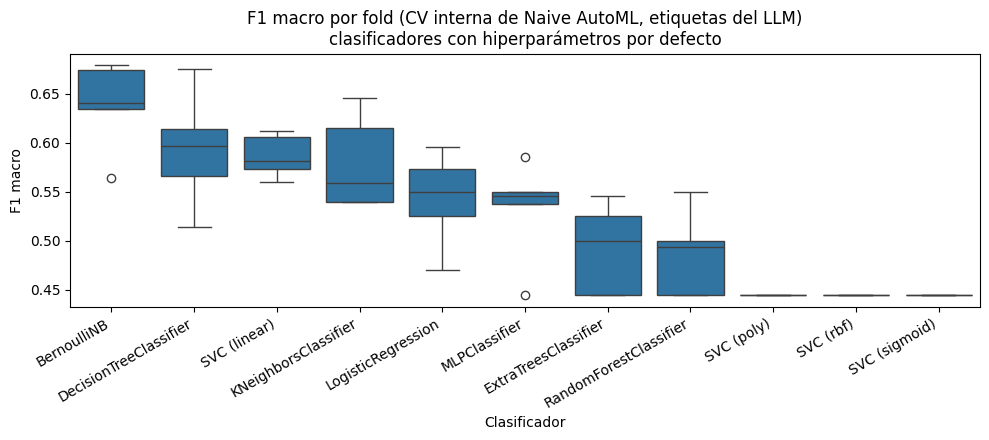

In [42]:
import re, ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

hist = naml.history.copy()
hist = hist[hist["status"] == "ok"]

# Solo clasificadores con hiperparámetros por defecto y sin preprocesadores
base = hist[(hist["default_hp"] == True)
            & hist["data-pre-processor_class"].isna()
            & hist["feature-pre-processor_class"].isna()]

def nombre_modelo(r):
    n = r["learner_class"].split(".")[-1]
    if n == "SVC":                                   # separar SVC por kernel
        k = re.search(r"kernel='(\w+)'", str(r["pipeline"]))
        n += f" ({k.group(1) if k else 'rbf'})"
    return n

largo = [{"Clasificador": nombre_modelo(r), "F1 macro": f}
         for _, r in base.iterrows()
         for f in (ast.literal_eval(r["evaluation_report"]) if isinstance(r["evaluation_report"], str)
                   else r["evaluation_report"])["f1_macro"]]

df_box = pd.DataFrame(largo)
orden = df_box.groupby("Clasificador")["F1 macro"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df_box, x="Clasificador", y="F1 macro", order=orden)
plt.xticks(rotation=30, ha="right")
plt.title("F1 macro por fold (CV interna de Naive AutoML, etiquetas del LLM)\n"
          "clasificadores con hiperparámetros por defecto")
plt.tight_layout()
plt.savefig("boxplot_clasificadores.png", dpi=200, bbox_inches="tight")
plt.show()

In [62]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.naive_bayes import BernoulliNB

def crear_pipeline():
    """Modelo final (Motivo de consulta): W2V + TF-IDF (1-3 gramas, min_df=3) + selección del 10 % de variables + BernoulliNB."""
    return Pipeline([
        ("union", FeatureUnion([
            ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
            ("w2v",   W2VFinal()),
        ])),
        ("esc", MaxAbsScaler()),
        ("sel", SelectPercentile(score_func=f_classif, percentile=10)),
        ("nb",  BernoulliNB()),
    ])

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, roc_auc_score, RocCurveDisplay,
                             ConfusionMatrixDisplay, confusion_matrix)

Xtr, Xva, Xte = X_train.fillna(""), X_val.fillna(""), X_test.fillna("")

# Modelo final: SOLO train (etiquetas LLM)
final = crear_pipeline().fit(Xtr, y_train)

¿Más datos mejorarían el modelo? ¿Memoriza?

AUC val: 0.894 | AUC test: 0.656


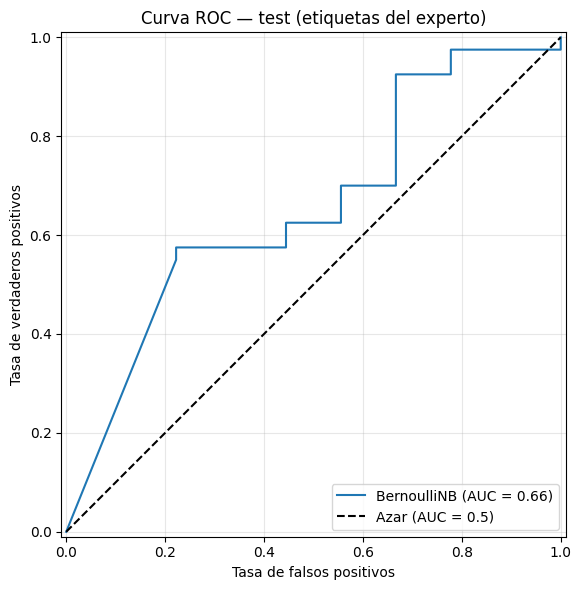

In [64]:
score_te = final.predict_proba(Xte)[:, 1]  
auc_te = roc_auc_score(y_test, score_te)
auc_va = roc_auc_score(y_val, final.predict_proba(Xva)[:, 1])
print(f"AUC val: {auc_va:.3f} | AUC test: {auc_te:.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, score_te, ax=ax, name="BernoulliNB")   # el AUC lo agrega solo
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set(title="Curva ROC — test (etiquetas del experto)",
       xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("curva_roc_test.png", dpi=200, bbox_inches="tight"); plt.show()

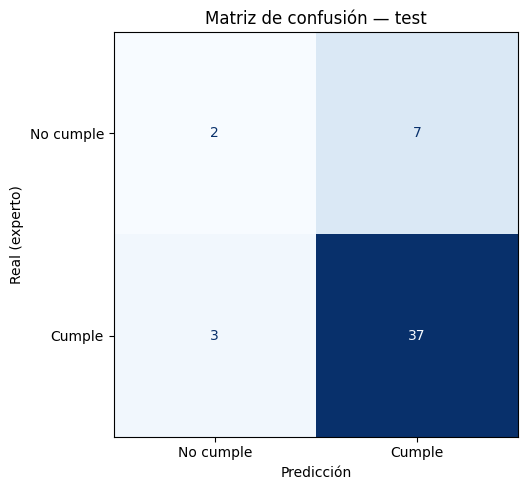

In [65]:
pred_te = final.predict(Xte)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_te, labels=[0, 1]),
                       display_labels=["No cumple", "Cumple"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Matriz de confusión — test", xlabel="Predicción", ylabel="Real (experto)")
plt.tight_layout(); plt.savefig("matriz_confusion_test.png", dpi=200, bbox_inches="tight"); plt.show()

In [66]:
from sklearn.metrics import classification_report, f1_score

pred_val  = final.predict(Xva)
pred_test = final.predict(Xte)

print("F1 macro val  (experto):", round(f1_score(y_val,  pred_val,  average="macro"), 3))
print("F1 macro test (experto):", round(f1_score(y_test, pred_test, average="macro"), 3))
print()
print(classification_report(y_test, pred_test, digits=3,
                            target_names=["No cumple (0)", "Cumple (1)"]))

F1 macro val  (experto): 0.728
F1 macro test (experto): 0.583

               precision    recall  f1-score   support

No cumple (0)      0.400     0.222     0.286         9
   Cumple (1)      0.841     0.925     0.881        40

     accuracy                          0.796        49
    macro avg      0.620     0.574     0.583        49
 weighted avg      0.760     0.796     0.772        49



In [ ]:
### guarda en caso de caida del kernel

import os, types, dill

def guardar_sesion(ruta='resultados/sesion.pkl'):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    datos, omitidas = {}, []
    for nombre, valor in list(globals().items()):
        # saltar variables internas, módulos y cosas de Jupyter
        if nombre.startswith('_') or isinstance(valor, types.ModuleType) \
           or nombre in ('In', 'Out', 'exit', 'quit', 'get_ipython'):
            continue
        try:
            dill.dumps(valor)      # prueba si se puede guardar
            datos[nombre] = valor
        except Exception:
            omitidas.append(nombre)
    with open(ruta, 'wb') as f:
        dill.dump(datos, f)
    print(f'Guardadas {len(datos)} variables.')
    if omitidas:
        print('No se pudieron guardar:', omitidas)


guardar_sesion()

Guardadas 160 variables.
No se pudieron guardar: ['naml']


In [2]:
### Carga en caso de caida del kernel

import dill

def cargar_sesion(ruta='resultados/sesion.pkl'):
    with open(ruta, 'rb') as f:
        globals().update(dill.load(f))
    print('Sesión restaurada.')

cargar_sesion()

Sesión restaurada.


## Conclusiones — Criterio Motivo de consulta

### 1. Datos

- **Entrenamiento:** 899 notas etiquetadas por el LLM (few-shot).
- **Validación y test:** 98 notas etiquetadas por el experto (80 cumple / 18 no cumple), divididas de forma estratificada en validación (40 / 9) y test (40 / 9).
- Ninguna nota del experto se usó para entrenar.

### 2. Tokenización y representación

Se compararon 3 tokenizaciones × 4 representaciones con regresión logística (validación cruzada anidada sobre las 98 notas del experto). Mejores combinaciones:

| Tokenización | Representación | F1 macro | Recall "No cumple" |
|---|---|---|---|
| Sin números | TF-IDF | **0.643** ± 0.150 | 0.350 |
| Con números | TF-IDF | 0.617 ± 0.140 | 0.300 |
| Con números | W2V + TF-IDF | 0.583 ± 0.148 | 0.333 |
| Sin números | W2V + TF-IDF | 0.583 ± 0.132 | **0.400** |
| Número genérico | W2V + TF-IDF | 0.583 ± 0.118 | 0.350 |

En la comparación con y sin stopwords, las dos mejores fueron TF-IDF con stopwords (0.643) y **W2V + TF-IDF sin stopwords (0.636)**.

- La combinación con mayor F1 macro fue **TF-IDF sin números (0.643)**.
- Se eligió **W2V + TF-IDF sin números y sin stopwords** porque W2V + TF-IDF sin números obtuvo el **mayor recall de "No cumple" (0.400)** y, sin stopwords, un F1 casi igual al mejor (0.636). En auditoría es prioritario detectar los incumplimientos.
- A diferencia de Examen físico y Diagnóstico, en este criterio **conservar los números no mejoró** la clasificación: el motivo de consulta se expresa con palabras ("acude por", "consulta por", "remitido para"), no con valores numéricos.
- Las diferencias entre combinaciones (≈ 0.01–0.06) son menores que la desviación entre folds (0.12–0.15), por lo que no son estadísticamente concluyentes.

Representación final: **W2V + TF-IDF (1-3 gramas, `min_df=3`), sin números ni stopwords, escalado con `MaxAbsScaler`** (22 879 dimensiones: 22 779 de TF-IDF + 100 de W2V).

### 3. Selección del clasificador (Naive AutoML)

- El AutoML completó la selección de algoritmos (32/32) y el ajuste de hiperparámetros (20 iteraciones), usando validación cruzada sobre las etiquetas del LLM.
- El mejor fue **BernoulliNB** (mediana de F1 ≈ 0.64), seguido del árbol de decisión (≈ 0.60) y SVC lineal (≈ 0.58).
- SVC con kernels poly, rbf y sigmoid quedaron en F1 ≈ 0.445, lo que equivale a predecir siempre "Cumple".
- El pipeline elegido incluye una **selección de variables**: `SelectPercentile` conserva el 10 % de las columnas más asociadas a la etiqueta (prueba ANOVA F). Todos los pasos usan hiperparámetros por defecto.

Modelo final: **W2V + TF-IDF → `MaxAbsScaler` → selección del 10 % de variables → BernoulliNB**. Reproduce exactamente el resultado del AutoML en validación (F1 macro = 0.728).

Nota: BernoulliNB convierte cada variable en 0/1. En las columnas TF-IDF equivale a "¿aparece el término?"; en las de W2V solo conserva el signo de cada dimensión, por lo que la parte W2V aporta poca información a este clasificador.

### 4. Curva de aprendizaje

- El F1 de entrenamiento está entre 0.93 y 0.97: gracias a la selección de variables, el modelo memoriza menos que en los otros criterios.
- El F1 de validación sube de ≈ 0.60 (180 notas) a ≈ 0.73 (899 notas) y no se estabiliza. **Más notas etiquetadas por el LLM probablemente mejorarían el modelo.**

### 5. Resultado final

| Clase | Precisión | Recall | F1 | Notas |
|---|---|---|---|---|
| No cumple (0) | 0.400 | 0.222 | 0.286 | 9 |
| Cumple (1) | 0.841 | 0.925 | 0.881 | 40 |
| **Macro** | **0.620** | **0.574** | **0.583** | 49 |

*Test, etiquetas del experto.*

| Métrica | Validación | Test |
|---|---|---|
| F1 macro | 0.728 | 0.583 |
| AUC | 0.894 | 0.656 |
| Accuracy | — | 0.796 |

- En test, el modelo detecta solo **2 de las 9 notas que no cumplen**: de las 5 que marcó como "No cumple", 2 eran correctas. Clasifica correctamente 37 de las 40 que cumplen.
- **El desempeño cae de forma marcada de validación a test** (F1 de 0.728 a 0.583; AUC de 0.894 a 0.656). Con 9 notas "No cumple" por conjunto, parte de la diferencia se debe a la variabilidad de muestras pequeñas, pero la caída es mayor que en los otros criterios. Indica que **el modelo no generaliza bien la detección de notas sin motivo de consulta**.
- Es el criterio con el menor desempeño de los tres.

### 6. Comparación entre criterios

| Criterio | Modelo | F1 val | F1 test | "No cumple" detectados (test) |
|---|---|---|---|---|
| Examen físico | TF-IDF (1-3) + BernoulliNB | 0.864 | 0.728 | 5 de 9 |
| Diagnóstico | TF-IDF (1-3) + Árbol de decisión | 0.680 | 0.751 | 5 de 9 |
| Motivo de consulta | W2V + TF-IDF + selección 10 % + BernoulliNB | 0.728 | 0.583 | 2 de 9 |

- Cada criterio quedó con una representación y un clasificador distintos, coherente con que cada uno depende de partes diferentes de la nota clínica.
- Motivo de consulta es el más difícil de detectar. Una posible explicación es que el motivo suele aparecer en una sola frase al inicio de la nota ("acude por…"), y su ausencia es difícil de capturar con representaciones que resumen la nota completa.

### 7. Limitaciones y trabajo futuro

- **Muestra pequeña del experto:** 98 notas, con solo 18 "No cumple", hacen que las métricas tengan alta variabilidad.
- **Selección de la representación:** la comparación de tokenizaciones y representaciones se hizo con validación cruzada sobre las 98 notas del experto, que incluyen las de test. Esto puede introducir un sesgo optimista; con más notas del experto, la selección debería hacerse solo con validación.
- **Dependencia de las etiquetas del LLM:** el modelo aprende a imitar al LLM. Medir el acuerdo entre el LLM y el experto permitiría estimar el techo de desempeño.
- **Más datos:** la curva de aprendizaje sugiere que más notas etiquetadas mejorarían el modelo.
- **Enfoque en la sección relevante:** como el motivo de consulta suele estar al inicio de la nota, usar solo las primeras frases podría reducir el ruido.
- **Representaciones:** probar embeddings preentrenados (modelos multilingües o clínicos en español), que capturan mejor el significado de frases como "acude por" o "consulta por".

verificar sobreajuste

Entender los resultados del objetivo 3

Reducir el df train 


verificar sobreajuste

Entender los resultados del objetivo 3

Reducir el df train 